# 02: Text units + unsupervised baseline (TextTiling over embeddings)

**Questions this notebook answers:**
1. **Text unit.** Which unit (sentence vs fixed block) loses the least precision when boundaries snap onto units? That is the ceiling on what any model can achieve.
2. **Encoder.** Does `e5-small` or `MiniLM` separate topics better?
3. **Baseline.** Which window works best for the TextTiling baseline? That score is **the bar the BiLSTM has to clear** (the shipping rule, 0009 §7).

Also reported:
- a **random** floor
- two chapter-count settings:
  - the **product setting**: ~6/h, "few and broad"
  - the **oracle count**: the true number of chapters. This separates "does it find *where*" from "does it guess *how many*".

Metrics: `lib/metrics.py`, identical to Chapter-Llama's (checked in the README log).

`DATASET` picks the videos:
- `prelim`: Chapter-Llama's `sml300_val` subset (300 English videos, ≤ 60 min). Used to get started while `asrs.json` downloads.
- `val`: our validation split from `01_data` (en + `es_val`). This is the official run.

In [1]:
import json, time, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from dotenv import load_dotenv
load_dotenv('../.env')
from lib import data as d, vidchapters as vc
from lib.units import UnitConfig
from lib.encode import Encoder
from lib.baseline import boundary_scores
from lib.decoding import DecodeConfig, decode
from lib.evaluate import Prediction, evaluate

DATASET = 'prelim'
ROOT = d.data_root()
if DATASET == 'prelim':
    videos = vc.load_subset(ROOT / 'raw/subsets/chapters_sml300_val.json', ROOT / 'raw/subsets/asrs_sml300_val.json')
else:
    videos = [v for s in ('val', 'es_val') for v in vc.load_jsonl(ROOT / f'interim/{s}.jsonl')]
RUN = Path(f'runs/2026-09-27-baseline-{DATASET}'); RUN.mkdir(parents=True, exist_ok=True)
EMB_DIR = ROOT / 'embeddings' / f'02-{DATASET}'; EMB_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
dur = pd.Series([v.duration / 60 for v in videos])
print(f'{len(videos)} videos, duration min median/max {dur.median():.0f}/{dur.max():.0f}, device {DEVICE}')

/home/pablo/projects/new_youtube_suite/backend/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


300 videos, duration min median/max 20/60, device cuda


## 1. Text units and their ceiling

When every reference boundary is moved to the nearest unit start, how much F1@3s/5s is left? A 10 s block, for example, can place a boundary up to 5 s away from the real moment.

In [2]:
UNIT_CONFIGS = {
    'sentence': UnitConfig(mode='sentence', min_s=2, max_s=15),
    'block5': UnitConfig(mode='block', block_s=5),
    'block10': UnitConfig(mode='block', block_s=10),
}
units = {k: {v.vid: vc.units_for(v, c) for v in videos} for k, c in UNIT_CONFIGS.items()}
rows = []
for k in UNIT_CONFIGS:
    preds = []
    for v in videos:
        us = [u.start for u in units[k][v.vid]]
        snapped = [0.0] + [us[i] for i in vc.boundary_units(us, v.chapter_starts)]
        preds.append(Prediction(v.vid, v.duration, us, v.chapter_starts, snapped))
    r = evaluate(preds)
    n_units = [len(units[k][v.vid]) for v in videos]
    sec = [np.mean([u.end - u.start for u in units[k][v.vid]]) for v in videos]
    rows.append(dict(unit=k, units_per_video=np.median(n_units), sec_per_unit=np.median(sec),
                     ceiling_F1_3s=r['F1@3s'], ceiling_F1_5s=r['F1@5s']))
pd.DataFrame(rows).set_index('unit').round(2)

,units_per_video,sec_per_unit,ceiling_F1_3s,ceiling_F1_5s
unit,,,,
sentence,143.5,5.96,72.82,83.28
block5,116.0,8.05,67.78,83.23
block10,75.5,12.71,47.19,70.82


## 2. Encoding (frozen), cached on the second drive

In [3]:
ENCODER_KEYS = ['e5-small', 'minilm']
emb = {}
for ek in ENCODER_KEYS:
    enc = None
    for uk in UNIT_CONFIGS:
        path = EMB_DIR / f'{ek}-{uk}.npz'
        if path.exists():
            z = np.load(path); emb[ek, uk] = {vid: z[vid] for vid in z.files}; continue
        enc = enc or Encoder(ek, device=DEVICE)
        t0 = time.time()
        emb[ek, uk] = {v.vid: enc([u.text for u in units[uk][v.vid]]).astype(np.float16) for v in videos}
        np.savez(path, **emb[ek, uk])
        n = sum(len(x) for x in emb[ek, uk].values())
        print(f'{ek}/{uk}: {n} units in {time.time()-t0:.0f}s ({n/(time.time()-t0):.0f}/s)')
    del enc; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5534.19it/s]

e5-small/sentence: 55290 units in 111s (496/s)


e5-small/block5: 42443 units in 88s (480/s)


e5-small/block10: 27135 units in 69s (395/s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2021.17it/s]

minilm/sentence: 55290 units in 109s (508/s)


minilm/block5: 42443 units in 87s (490/s)


minilm/block10: 27135 units in 66s (413/s)


## 3. TextTiling baseline: encoder × unit × window

- The window is in **seconds** (converted to units), so it means the same thing for every unit size.
- **Product decoding:** `DecodeConfig(per_hour=6, min_len_s=60)`.
- **Oracle decoding:** the same, but asking for exactly the true number of chapters.

In [4]:
def run(scores_fn, uk, oracle=False):
    preds = []
    for v in videos:
        us = [u.start for u in units[uk][v.vid]]
        if not us: continue
        s = scores_fn(v, uk)
        cfg = DecodeConfig(per_hour=6, min_len_s=60)
        if oracle:
            n = len([t for t in v.chapter_starts if t > 0]) + 1
            cfg = DecodeConfig(per_hour=n / (v.duration / 3600), min_chapters=min(3, n), min_len_s=60)
        preds.append(Prediction(v.vid, v.duration, us, v.chapter_starts, decode(s, us, v.duration, cfg)))
    return evaluate(preds)

def unit_seconds(uk):
    return np.median([np.mean([u.end - u.start for u in units[uk][v.vid]]) for v in videos if units[uk][v.vid]])

results = []
rng = np.random.default_rng(0)
for uk in UNIT_CONFIGS:
    for oracle in (False, True):
        r = run(lambda v, uk: rng.random(len(units[uk][v.vid])), uk, oracle)
        results.append(dict(method='random', encoder='-', unit=uk, window_s=None, oracle=oracle, **r))
for ek, uk, win_s in itertools.product(ENCODER_KEYS, UNIT_CONFIGS, (60, 120, 240)):
    w = max(1, round(win_s / unit_seconds(uk)))
    for oracle in (False, True):
        r = run(lambda v, uk: boundary_scores(emb[ek, uk][v.vid].astype(np.float32), window=w), uk, oracle)
        results.append(dict(method='texttiling', encoder=ek, unit=uk, window_s=win_s, oracle=oracle, **r))
res = pd.DataFrame(results)
cols = ['method', 'encoder', 'unit', 'window_s', 'F1@5s', 'F1@3s', 'F1@30s', 'tIoU-F1', 'Pk', 'WindowDiff', 'count_MAE', 'pred_chapters_mean', 'ref_chapters_mean']
print('PRODUCT setting (~6/h)'); display(res[~res.oracle][cols].sort_values('F1@5s', ascending=False).head(12))
print('ORACLE count'); display(res[res.oracle][cols].sort_values('F1@5s', ascending=False).head(12))

PRODUCT setting (~6/h)


,method,encoder,unit,window_s,F1@5s,F1@3s,F1@30s,tIoU-F1,Pk,WindowDiff,count_MAE,pred_chapters_mean,ref_chapters_mean
20,texttiling,e5-small,block10,120.0,12.404,9.342,34.173,17.116,0.395,0.404,5.467,3.373,8.733
30,texttiling,minilm,block5,60.0,11.941,8.463,30.245,15.201,0.406,0.413,5.473,3.367,8.733
36,texttiling,minilm,block10,60.0,11.605,8.535,32.606,15.572,0.403,0.411,5.473,3.367,8.733
18,texttiling,e5-small,block10,60.0,11.515,9.220,31.707,15.801,0.404,0.413,5.463,3.377,8.733
38,texttiling,minilm,block10,120.0,11.512,8.082,34.684,16.715,0.399,0.407,5.467,3.373,8.733
6,texttiling,e5-small,sentence,60.0,11.219,8.326,29.589,15.334,0.405,0.413,5.470,3.370,8.733
8,texttiling,e5-small,sentence,120.0,11.051,7.766,30.956,15.235,0.398,0.406,5.467,3.373,8.733
40,texttiling,minilm,block10,240.0,10.999,7.969,32.355,16.459,0.394,0.404,5.470,3.370,8.733
32,texttiling,minilm,block5,120.0,10.737,7.071,32.601,15.630,0.397,0.406,5.470,3.370,8.733
16,texttiling,e5-small,block5,240.0,10.687,7.250,31.905,16.212,0.392,0.399,5.467,3.373,8.733


ORACLE count


,method,encoder,unit,window_s,F1@5s,F1@3s,F1@30s,tIoU-F1,Pk,WindowDiff,count_MAE,pred_chapters_mean,ref_chapters_mean
31,texttiling,minilm,block5,60.0,17.289,12.554,47.668,25.226,0.404,0.421,1.030,7.703,8.733
21,texttiling,e5-small,block10,120.0,17.168,13.177,51.416,26.711,0.386,0.402,1.037,7.697,8.733
19,texttiling,e5-small,block10,60.0,17.058,13.572,48.990,25.021,0.403,0.420,1.063,7.670,8.733
37,texttiling,minilm,block10,60.0,16.610,12.375,48.808,25.706,0.401,0.419,1.050,7.683,8.733
41,texttiling,minilm,block10,240.0,16.292,12.163,49.870,25.773,0.382,0.402,1.030,7.703,8.733
39,texttiling,minilm,block10,120.0,16.265,11.737,50.878,26.492,0.395,0.411,1.043,7.690,8.733
7,texttiling,e5-small,sentence,60.0,15.775,11.590,46.495,24.307,0.405,0.421,1.037,7.697,8.733
25,texttiling,minilm,sentence,60.0,15.660,11.282,46.328,24.077,0.410,0.427,1.013,7.720,8.733
33,texttiling,minilm,block5,120.0,15.586,10.818,49.152,25.575,0.392,0.409,1.000,7.733,8.733
27,texttiling,minilm,sentence,120.0,15.571,10.531,48.649,25.514,0.397,0.415,1.017,7.717,8.733


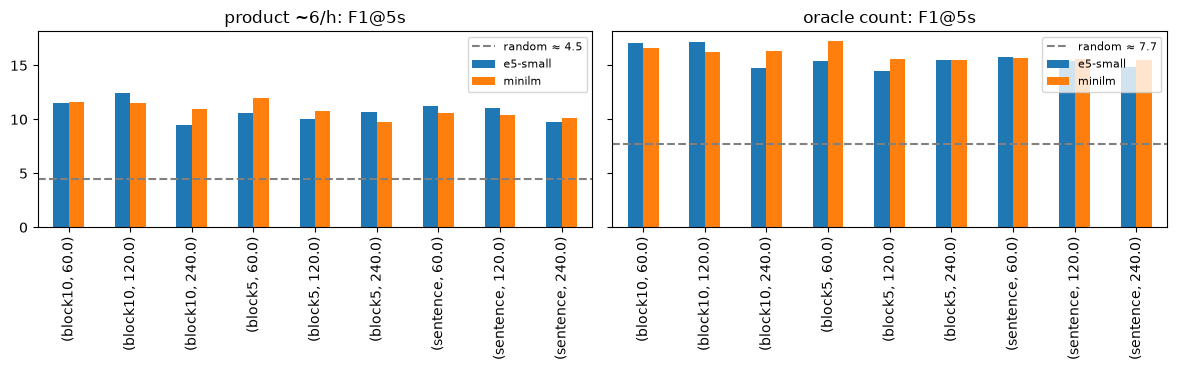

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, oracle in zip(axes, (False, True)):
    sub = res[(res.method == 'texttiling') & (res.oracle == oracle)]
    sub.pivot_table(index=['unit', 'window_s'], columns='encoder', values='F1@5s').plot.bar(ax=ax)
    rnd = res[(res.method == 'random') & (res.oracle == oracle)]['F1@5s'].mean()
    ax.axhline(rnd, color='grey', ls='--', label=f'random ≈ {rnd:.1f}'); ax.legend(fontsize=8)
    ax.set_title(('oracle count' if oracle else 'product ~6/h') + ': F1@5s'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig(RUN / 'baseline_f1_5s.png', dpi=110); plt.show()

## 4. A video up close: similarity curve, real boundaries and predicted boundaries

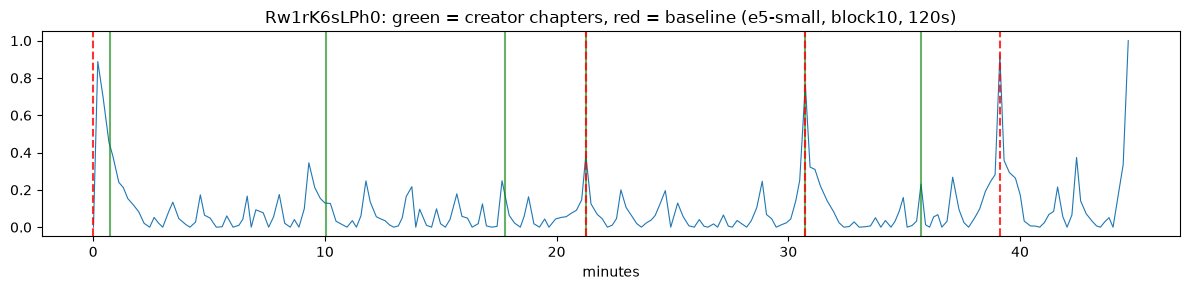

[(0.7, 'Jim\'s new book, "Unwarranted Influence'),
 (10.0, 'Does a military-industrial complex drive US policy'),
 (17.8, 'Evaluating the "merchants of death" thesis'),
 (21.2, 'America, arms dealer to the world'),
 (30.7, 'Will the Tea Party attack military spending'),
 (35.7, "Why Eisenhower's speech still resonates")]

In [6]:
best = res[(res.method == 'texttiling') & ~res.oracle].sort_values('F1@5s', ascending=False).iloc[0]
ek, uk, win_s = best.encoder, best.unit, int(best.window_s); w = max(1, round(win_s / unit_seconds(uk)))
v = sorted(videos, key=lambda v: abs(v.duration - 45 * 60))[0]
us = [u.start for u in units[uk][v.vid]]
s = boundary_scores(emb[ek, uk][v.vid].astype(np.float32), window=w)
pred = decode(s, us, v.duration, DecodeConfig(per_hour=6, min_len_s=60))
plt.figure(figsize=(12, 3)); plt.plot(np.array(us) / 60, s, lw=.8, label='boundary score')
for t in v.chapter_starts: plt.axvline(t / 60, color='green', alpha=.6)
for t in pred: plt.axvline(t / 60, color='red', ls='--', alpha=.8)
plt.xlabel('minutes'); plt.title(f'{v.vid}: green = creator chapters, red = baseline ({ek}, {uk}, {win_s}s)')
plt.tight_layout(); plt.savefig(RUN / 'example_video.png', dpi=110); plt.show()
list(zip([round(t / 60, 1) for t in v.chapter_starts], v.chapter_titles))

In [7]:
json.dump(dict(dataset=DATASET, n_videos=len(videos), unit_configs={k: c.__dict__ for k, c in UNIT_CONFIGS.items()},
               encoders=ENCODER_KEYS, windows_s=[60, 120, 240], decode_product=dict(per_hour=6, min_len_s=60)),
          open(RUN / 'config.json', 'w'), indent=1)
res.to_csv(RUN / 'results.csv', index=False)
json.dump(dict(best_product=best.to_dict()), open(RUN / 'metrics.json', 'w'), indent=1, default=str)
print('saved to', RUN)

saved to runs/2026-09-27-baseline-prelim
